In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np

In [2]:
from sklearn.linear_model import LinearRegression
from sklearn.preprocessing import PolynomialFeatures,StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.metrics import r2_score , mean_squared_error
from sklearn.pipeline import Pipeline

** from sklearn.pipeline import Pipeline ** => 2 Modeli Arka arkaya çalıştırmak için kullanıyoruz.

In [3]:
df = pd.read_csv('C:/Users/iskit/Desktop/Machine-Learning-Studies/03-MachineLearning/datasets/customersatisfaction.csv')

In [4]:
df.head()

,Unnamed: 0,Customer Satisfaction,Incentive
0,0,-1.282447,1.010513
1,1,0.425298,2.281043
2,2,1.953070,4.415053
3,3,2.625838,10.563600
4,4,-1.426333,0.627365


In [5]:
df.drop('Unnamed: 0',axis=1,inplace=True)

In [6]:
df.head()

,Customer Satisfaction,Incentive
0,-1.282447,1.010513
1,0.425298,2.281043
2,1.953070,4.415053
3,2.625838,10.563600
4,-1.426333,0.627365


In [7]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 100 entries, 0 to 99
Data columns (total 2 columns):
 #   Column                 Non-Null Count  Dtype  
---  ------                 --------------  -----  
 0   Customer Satisfaction  100 non-null    float64
 1   Incentive              100 non-null    float64
dtypes: float64(2)
memory usage: 1.7 KB


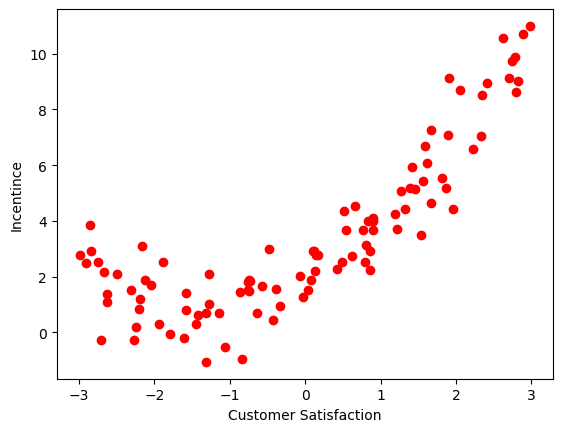

In [8]:
plt.scatter(df['Customer Satisfaction'],df['Incentive'],c='r')
plt.xlabel('Customer Satisfaction')
plt.ylabel('Incentince')
plt.show()

In [9]:
# dependent & independent features

In [10]:
X = df[['Customer Satisfaction']]
y = df['Incentive']

In [11]:
X.head()

,Customer Satisfaction
0,-1.282447
1,0.425298
2,1.953070
3,2.625838
4,-1.426333


In [12]:
y.head()

0     1.010513
1     2.281043
2     4.415053
3    10.563600
4     0.627365
Name: Incentive, dtype: float64

In [13]:
# train - test split

In [14]:
X_train,X_test,y_train,y_test=train_test_split(X,y,test_size=0.20,random_state=15)

In [15]:
X_train

,Customer Satisfaction
99,0.512504
3,2.625838
20,-0.865714
55,-1.145369
6,2.823460
...,...
28,1.191020
0,-1.282447
5,-1.311432
12,0.490521


In [16]:
scaler = StandardScaler()

In [17]:
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

In [18]:
regression = LinearRegression()

In [19]:
regression.fit(X,y)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [20]:
## prediction

In [21]:
y_pred = regression.predict(X_test)

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


In [22]:
y_pred

array([4.00870152, 3.50280105, 2.38149685, 4.89359846, 3.36710005,
       4.60307316, 4.02804589, 3.44723207, 4.53097645, 1.56855226,
       3.91289553, 4.09312442, 2.35018385, 1.66052257, 4.34311203,
       1.72093404, 1.09731863, 1.31964015, 3.41642285, 2.1423167 ])

In [23]:
score = r2_score(y_test,y_pred)
score

0.439975185629331

C:\ProgramData\anaconda3\Lib\site-packages\sklearn\utils\validation.py:2749: UserWarning: X does not have valid feature names, but LinearRegression was fitted with feature names
  warnings.warn(


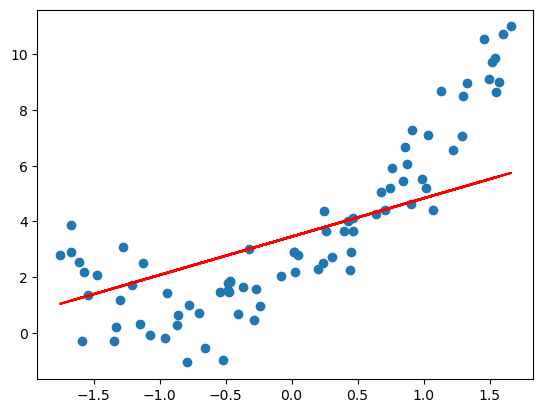

In [24]:
plt.scatter(X_train,y_train)
plt.plot(X_train,regression.predict(X_train),color='r')
plt.show()

In [25]:
# include_bias = True demek intercepte denklemdeki sabit değeri al demek
poly = PolynomialFeatures(degree=2,include_bias=True)

In [26]:
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)

In [27]:
X_train_poly

array([[ 1.00000000e+00,  2.47633535e-01,  6.13223675e-02],
       [ 1.00000000e+00,  1.45565669e+00,  2.11893639e+00],
       [ 1.00000000e+00, -5.40182671e-01,  2.91797318e-01],
       [ 1.00000000e+00, -7.00039198e-01,  4.90054879e-01],
       [ 1.00000000e+00,  1.56862116e+00,  2.46057233e+00],
       [ 1.00000000e+00,  9.87568378e-01,  9.75291302e-01],
       [ 1.00000000e+00,  4.48640749e-01,  2.01278522e-01],
       [ 1.00000000e+00,  1.54377517e+00,  2.38324178e+00],
       [ 1.00000000e+00,  1.33219938e+00,  1.77475518e+00],
       [ 1.00000000e+00, -4.80410926e-01,  2.30794658e-01],
       [ 1.00000000e+00,  3.92892957e-01,  1.54364876e-01],
       [ 1.00000000e+00, -6.57456685e-01,  4.32249293e-01],
       [ 1.00000000e+00,  4.42663768e-01,  1.95951211e-01],
       [ 1.00000000e+00, -8.72131603e-01,  7.60613533e-01],
       [ 1.00000000e+00, -1.57257044e+00,  2.47297780e+00],
       [ 1.00000000e+00, -4.70184630e-01,  2.21073587e-01],
       [ 1.00000000e+00, -8.36083500e-02

In [28]:
regression = LinearRegression()
regression.fit(X_train_poly,y_train)

,fit_intercept,True
,copy_X,True
,tol,1e-06
,n_jobs,None
,positive,False


In [29]:
y_pred = regression.predict(X_test_poly)
r2_score = r2_score(y_test,y_pred)
print('Score: ',r2_score)

Score:  0.7685687698788557


In [30]:
regression.coef_

array([0.        , 2.63871762, 1.54959954])

In [31]:
regression.intercept_

np.float64(2.076676429793282)

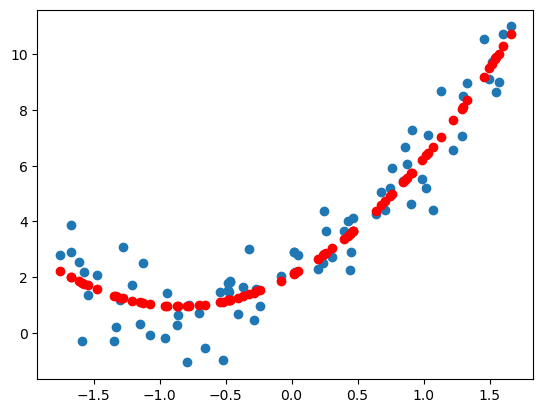

In [32]:
plt.scatter(X_train,y_train)
plt.scatter(X_train,regression.predict(X_train_poly),color='r')
plt.show()

In [33]:
from sklearn.metrics import r2_score

poly = PolynomialFeatures(degree=3,include_bias=True)
X_train_poly = poly.fit_transform(X_train)
X_test_poly = poly.transform(X_test)
regression = LinearRegression()
regression.fit(X_train_poly,y_train)

y_pred = regression.predict(X_test_poly)
score = r2_score(y_test,y_pred)
print('Score: ',score)

Score:  0.7573443621401049


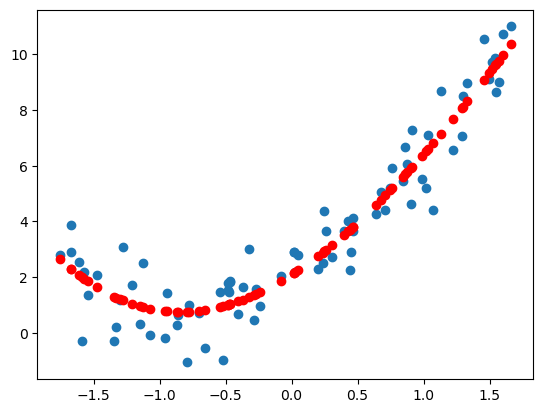

In [34]:
plt.scatter(X_train,y_train)
plt.scatter(X_train,regression.predict(X_train_poly),color='r')
plt.show()

In [35]:
# new data

In [36]:
new_df = pd.read_csv('C:/Users/iskit/Desktop/Machine-Learning-Studies/03-MachineLearning/datasets/newdatas.csv')

In [37]:
new_df

,0
0,-3.000000
1,-2.969849
2,-2.939698
3,-2.909548
4,-2.879397
...,...
195,2.879397
196,2.909548
197,2.939698
198,2.969849


In [38]:
new_df.rename(columns={'0':'Customer Satisfaction'},inplace=True)

In [39]:
new_df

,Customer Satisfaction
0,-3.000000
1,-2.969849
2,-2.939698
3,-2.909548
4,-2.879397
...,...
195,2.879397
196,2.909548
197,2.939698
198,2.969849


In [40]:
X_new = new_df[['Customer Satisfaction']]
X_new

,Customer Satisfaction
0,-3.000000
1,-2.969849
2,-2.939698
3,-2.909548
4,-2.879397
...,...
195,2.879397
196,2.909548
197,2.939698
198,2.969849


In [41]:
X_new = scaler.transform(X_new)

In [42]:
X_new_poly = poly.transform(X_new)

In [43]:
y_new = regression.predict(X_new_poly)

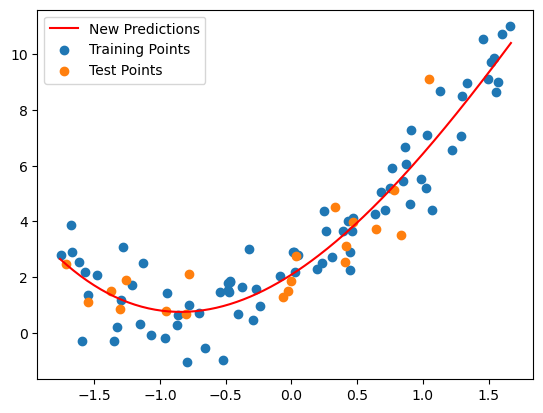

In [44]:
plt.plot(X_new,y_new,'r',label='New Predictions')
plt.scatter(X_train,y_train,label='Training Points')
plt.scatter(X_test,y_test,label='Test Points')
plt.legend()
plt.show()

In [45]:
# pipeline

In [46]:
def poly_regression(degree):
    poly_features = PolynomialFeatures(degree=degree)
    scaler = StandardScaler()
    lin_reg = LinearRegression()
    pipeline = Pipeline(
        [
            ('standard_scaler',scaler),
            ('poly_features',poly_features),
            ('lin_reg',lin_reg)
        ]
    )
    pipeline.fit(X_train,y_train)
    score = pipeline.score(X_test,y_test)
    print('R2 Score: ',score)

    y_pred_new = pipeline.predict(X_new)
    plt.plot(X_new,y_pred_new,'r',label='New Predictions')
    plt.scatter(X_train,y_train,label='Training Points')
    plt.scatter(X_test,y_test,label='Test Points')
    plt.legend()
    plt.show()

R2 Score:  0.2705652535622246


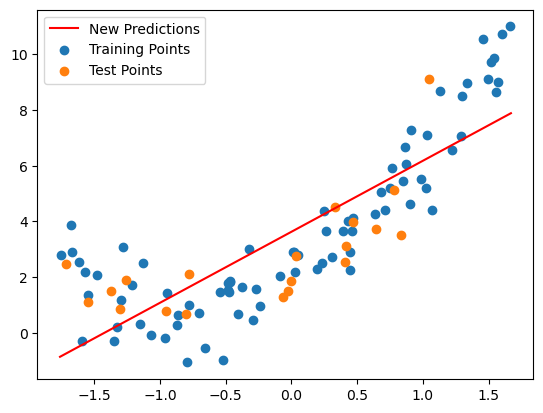

In [47]:
poly_regression(1)

R2 Score:  0.7685687698788557


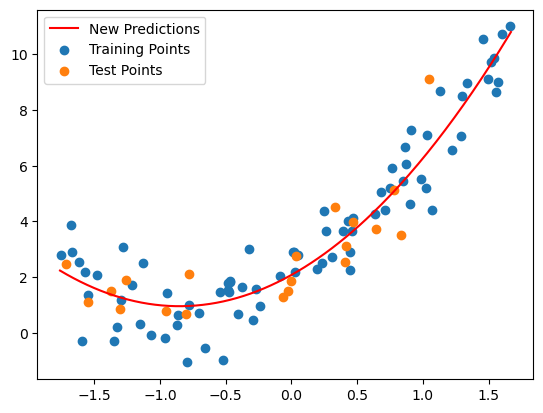

In [48]:
poly_regression(2)

R2 Score:  0.7573443621401049


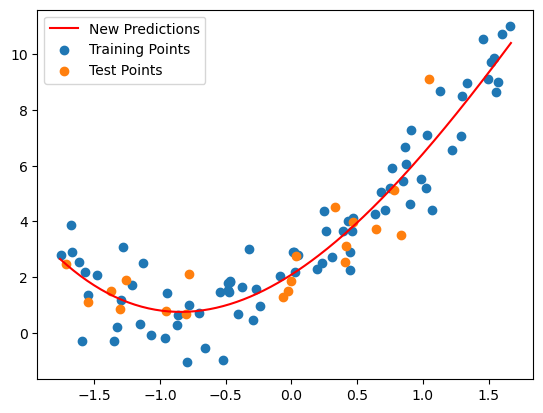

In [49]:
poly_regression(3)

R2 Score:  0.2705652535622246


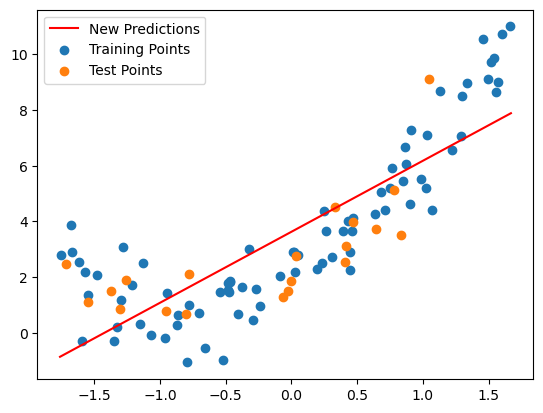

R2 Score:  0.7685687698788557


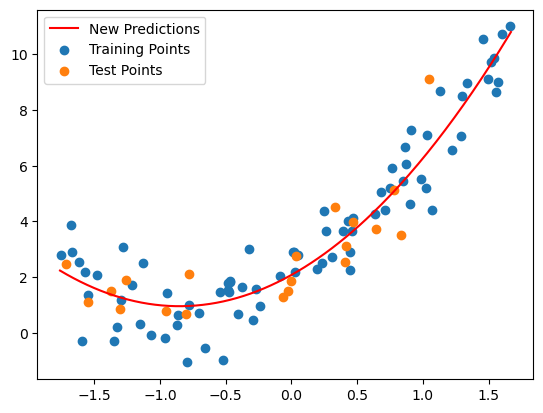

R2 Score:  0.7573443621401049


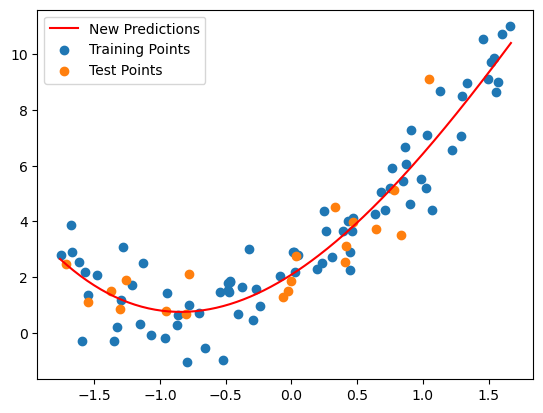

R2 Score:  0.7355034443260415


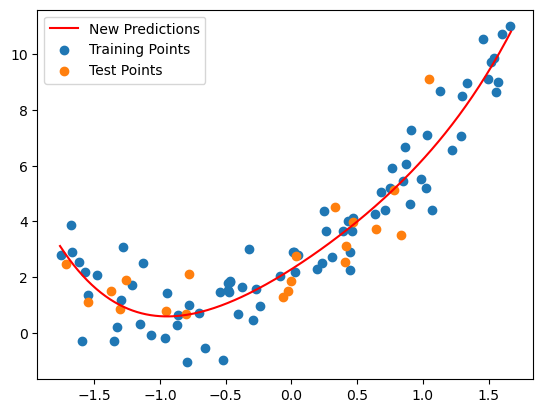

R2 Score:  0.7351244165095399


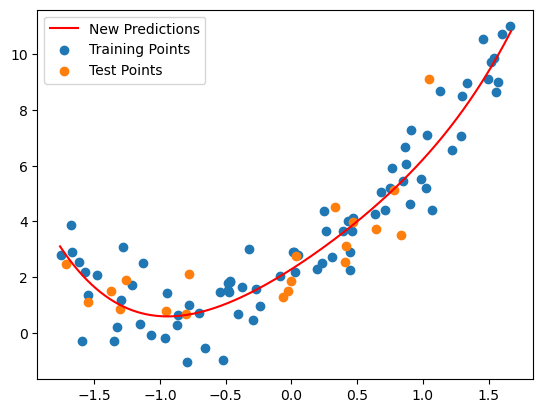

R2 Score:  0.7343590482133426


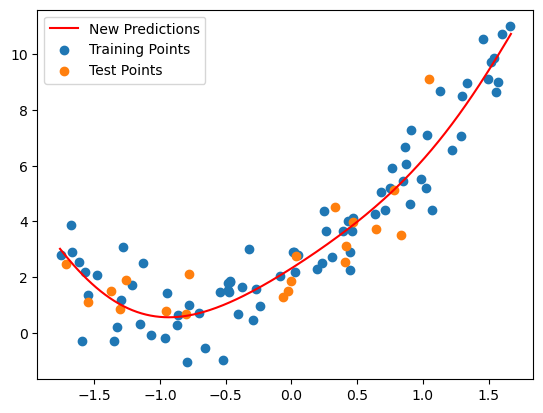

R2 Score:  0.7347819263549455


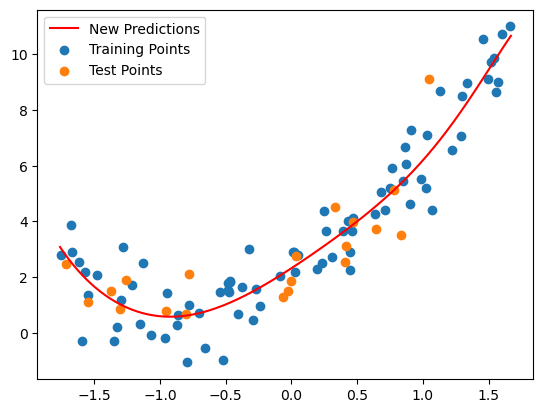

R2 Score:  0.7411422099998375


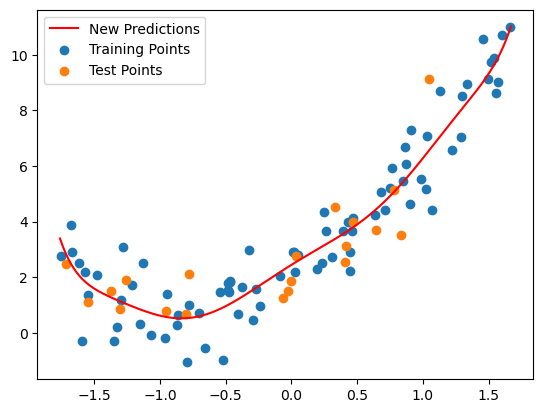

R2 Score:  0.731076387981594


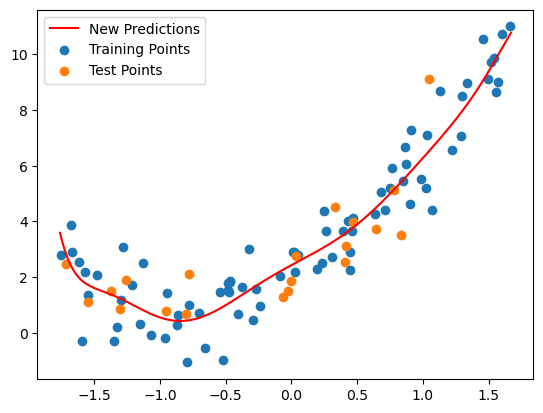

R2 Score:  0.7280578621232874


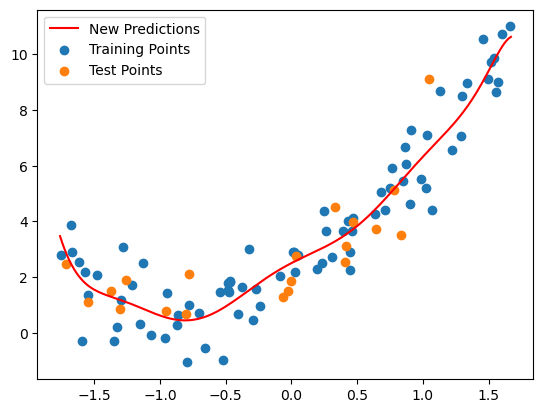

In [50]:
for degree in [1,2,3,4,5,6,7,8,9,10]:
    poly_regression(degree)